# 현실의 데이터 32: 축구: 이 슛은 골일까?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/32_football.ipynb)

**분야**: 스포츠 · 게임 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 스포츠 분석 · 기대 득점 (xG) · 확률 예측

> 슛 위치와 각도만 보고 골이 될 확률은? (기대 득점 xG)

**데이터**: StatsBomb Open Data · 2022 카타르 월드컵 64경기 (약 190MB (경기 64개)). StatsBomb 이 공개한 경기 이벤트 데이터 (패스 · 슛 · 태클마다 위치 · 시각 · 선수). 경기마다 JSON 파일 하나 (모두 약 190MB).

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 슛 한 번 |
| ② 입력 X | 골대까지 거리 · 각도 · 몸의 부위 (발/머리) · 슛 종류 · 압박 |
| ③ 출력 y | 골인가 (확률) |
| ④ 평가지표 | 로그 손실 (확률이 맞나) |
| ⑤ 기준선 | 모든 슛에 전체 골 비율 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Decroos et al. (2019) Actions Speak Louder Than Goals: Valuing Player Actions in Soccer, KDD](https://arxiv.org/abs/1802.07127)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

경기 목록 → 경기마다 이벤트 파일 (64개, 처음엔 2~3분).

In [2]:
import json
BASE = "https://raw.githubusercontent.com/statsbomb/open-data/master/data/"
matches = json.load(open(download(BASE + "matches/43/106.json", "data/statsbomb_matches_43_106.json")))
matches = sorted(matches, key=lambda m: m["match_date"])
print(len(matches), "matches,", matches[0]["match_date"], "~", matches[-1]["match_date"])

rows = []
for k, m in enumerate(matches):
    events = json.load(open(download(BASE + f"events/{m['match_id']}.json", f"data/sb_events_{m['match_id']}.json")))
    for e in events:
        if e["type"]["name"] == "Shot":
            s = e["shot"]
            rows.append(dict(match=k, x=e["location"][0], y=e["location"][1], body=s["body_part"]["name"], kind=s["type"]["name"],
                             pressure=int(e.get("under_pressure", False)), first_time=int(s.get("first_time", False)),
                             goal=int(s["outcome"]["name"] == "Goal"), sb_xg=s["statsbomb_xg"], team=e["team"]["name"]))
shots = pd.DataFrame(rows)
print(shots.shape, f"goal rate {shots['goal'].mean():.1%}")
shots.sample(5, random_state=0)

64 matches, 2022-11-20 ~ 2022-12-18


(1494, 10) goal rate 13.1%


,match,x,y,body,kind,pressure,first_time,goal,sb_xg,team
799,37,113.9,52.3,Head,Open Play,1,0,0,0.020116,Denmark
1047,47,92.8,40.0,Left Foot,Open Play,0,0,0,0.036436,Portugal
1436,62,115.6,39.0,Head,Open Play,0,0,1,0.417839,Morocco
54,2,112.8,35.7,Head,Open Play,0,0,0,0.160685,Senegal
793,37,98.3,20.9,Right Foot,Open Play,0,0,0,0.010397,Australia


## 열어 보기: 경기장 위의 슛

경기장은 120 × 80 (야드), 골대는 x = 120, y = 36 ~ 44. 골 (주황) 은 어디서 나왔을까?

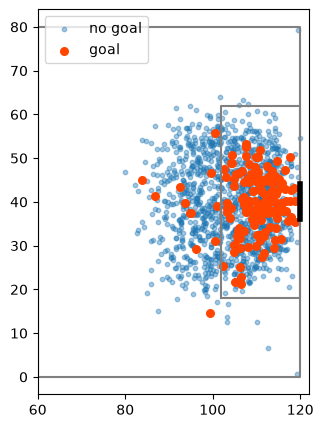

           mean  size
kind                 
Corner     0.00     2
Free Kick  0.04    46
Open Play  0.11  1382
Penalty    0.67    64


In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot([60, 120, 120, 60, 60], [0, 0, 80, 80, 0], color="gray"); ax.plot([102, 120, 120, 102, 102], [18, 18, 62, 62, 18], color="gray")
ax.scatter(shots.loc[shots.goal == 0, "x"], shots.loc[shots.goal == 0, "y"], s=10, alpha=0.4, label="no goal")
ax.scatter(shots.loc[shots.goal == 1, "x"], shots.loc[shots.goal == 1, "y"], s=30, color="orangered", label="goal")
ax.plot([120, 120], [36, 44], color="black", lw=4); ax.set_xlim(60, 122); ax.set_aspect("equal"); ax.legend(); plt.show()
print(shots.groupby("kind")["goal"].agg(["mean", "size"]).round(2))

## 문제 하나 골라 보기: 슛 → 골 확률

거리와 각도 (골대 두 기둥 사이로 보이는 각) 를 계산해 로지스틱회귀. **경기 단위 · 날짜 순서** 로 앞 48경기 학습, 뒤 16경기 (토너먼트) 시험.
StatsBomb 도 자기 모델의 확률 (`sb_xg`) 을 데이터에 넣어 두었다. 같이 비교한다.

In [4]:
from sklearn.linear_model import LogisticRegression

def log_loss(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def shot_features(shots):
    dx, dy = 120 - shots["x"], shots["y"] - 40
    angle = np.abs(np.arctan2(4 * dx, dx ** 2 + dy ** 2 - 16))          # angle between the two posts
    return pd.DataFrame({"dist": np.hypot(dx, dy), "angle": angle, "head": (shots["body"] == "Head").astype(int),
                         "penalty": (shots["kind"] == "Penalty").astype(int), "free_kick": (shots["kind"] == "Free Kick").astype(int),
                         "pressure": shots["pressure"], "first_time": shots["first_time"]})

X = shot_features(shots); y = shots["goal"].values
tr, te = shots["match"] < 48, shots["match"] >= 48
m = LogisticRegression(max_iter=2000).fit(X[tr], y[tr])
p = m.predict_proba(X[te])[:, 1]
print(f"test shots {te.sum()}, goals {y[te].sum()}")
print(f"baseline (goal rate {y[tr].mean():.3f} for every shot): log loss {log_loss(y[te], np.full(te.sum(), y[tr].mean())):.3f}")
print(f"our logistic (7 numbers)                : log loss {log_loss(y[te], p):.3f}")
print(f"StatsBomb's own xG                      : log loss {log_loss(y[te], shots.loc[te, 'sb_xg'].values):.3f}")
print(pd.Series(m.coef_[0], index=X.columns).round(2).to_dict())

test shots 428, goals 77
baseline (goal rate 0.111 for every shot): log loss 0.492
our logistic (7 numbers)                : log loss 0.351
StatsBomb's own xG                      : log loss 0.323
{'dist': -0.14, 'angle': 0.77, 'head': -0.82, 'penalty': 1.55, 'free_kick': 0.61, 'pressure': -0.64, 'first_time': 0.08}


**관찰**: 거리 · 각도 몇 개만으로도 기준선보다 확실히 낫고, 업체의 xG 모델 (수비수 · 골키퍼 위치까지 쓰는) 에 꽤 가깝다. 머리로 찬 슛은 같은 거리에서도 골 확률이 낮다.

## 다른 문제로 바꿔 보기

- **선수 평가**: 슛 하나가 아니라 '선수 × 경기' 를 한 행으로 하면? 실제 골 수 − 기대 골 (xG 합) = 운이 좋았나, 잘 찼나.
- **패스의 가치**: 한 행 = 패스, y = 이 패스 뒤 10초 안에 골이 났나 (VAEP, 아래 논문).

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |